<a href="https://colab.research.google.com/github/allnlk/ML/blob/main/%D0%9B%D0%A0_12_%D0%9A%D1%83%D0%B1%D1%80%D0%B0%D0%BA_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 12
## Рекурентні нейронні мережі (RNN, LSTM). Генерація тексту та підбір гіперпараметрів

**ПІБ студента:** Кубрак Аліна  
**Група:** 3-10  
**Дата:** 23.11

### Мета роботи
Ознайомитися з принципами обробки текстових послідовностей за допомогою **SimpleRNN** та **LSTM**, навчитися підготовлювати текстові дані, будувати й навчати модель передбачення наступного слова, генерувати текст і підбирати гіперпараметри за допомогою **Keras Tuner**.

### Очікуваний результат
- Побудована й навчена модель `Embedding → SimpleRNN → LSTM → Dropout → Dense`.
- Графіки втрат і точності, приклад згенерованого тексту.
- Результат автоматичного підбору гіперпараметрів і порівняння двох моделей.

**Інструкція:** виконуйте кроки послідовно, заповнюйте порожні комірки Python власним кодом. Не видаляйте результати запуску — вони потрібні для перевірки. Рекомендоване середовище: Google Colab або Jupyter Notebook з TensorFlow.

## Частина 1. Створення моделі для передбачення наступного слова

### 1. Імпорт бібліотек
Імпортуйте:
- `numpy` як `np`, `matplotlib.pyplot` як `plt`;
- `Sequential` із `tensorflow.keras.models`;
- `Dense`, `SimpleRNN`, `LSTM`, `Embedding`, `Dropout`;
- `Tokenizer` із `tensorflow.keras.preprocessing.text`;
- `to_categorical` із `tensorflow.keras.utils`.

**Завдання:** переконайтеся, що всі бібліотеки імпортуються без помилок.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, SimpleRNN, LSTM, Embedding, Dropout
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import to_categorical

### 2. Вхідний текст для навчання
Створіть рядкову змінну `texts` із наведеним фрагментом вірша. Саме цей текст використовується у вихідному прикладі лабораторної роботи.

```text
Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..

Чом вас вітер не розвіяв
В степу, як пилину?
Чом вас лихо не приспало,
Як свою дитину?..

Бо вас лихо на світ на сміх породило,
Поливали сльози... чом не затопили,
Не винесли в море, не розмили в полі?..
```

**Завдання:** виведіть початковий текст або перші 100 його символів.

In [2]:
texts = """Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..

Чом вас вітер не розвіяв
В степу, як пилину?
Чом вас лихо не приспало,
Як свою дитину?..

Бо вас лихо на світ на сміх породило,
Поливали сльози... чом не затопили,
Не винесли в море, не розмили в полі?.."""

print(texts[:100])

Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..

Чом вас вітер не розві


### 3. Попередня обробка та токенізація
1. Видаліть із `texts` можливий символ `\ufeff`.
2. Задайте `maxWordsCount = 1000`.
3. Створіть `Tokenizer` із такими налаштуваннями: `num_words=maxWordsCount`, `lower=True`, `split=' '`, `char_level=False`. Для `filters` використайте набір знаків пунктуації з вихідного прикладу, зокрема `!`, `?`, `.`, `,`, тире та лапки.
4. Навчіть токенізатор на тексті за допомогою `fit_on_texts()`.
5. Виведіть кількість знайдених унікальних слів та кілька відповідностей зі словника `word_index`.

**Підказка:** метод `fit_on_texts()` будує словник відповідностей слів і числових індексів.

In [3]:
texts = texts.replace('\ufeff', '')

maxWordsCount = 1000
tokenizer = Tokenizer(num_words=maxWordsCount,
                      filters='!–"—#$%&()*+,-./:;<=>?@[\\]^_`{|}~\t\n\r«»',
                      lower=True, split=' ', char_level=False)
tokenizer.fit_on_texts([texts])

print('Кількість унікальних слів:', len(tokenizer.word_index))
print(list(tokenizer.word_index.items())[:10])

Кількість унікальних слів: 35
[('не', 1), ('лихо', 2), ('на', 3), ('чом', 4), ('вас', 5), ('в', 6), ('думи', 7), ('мої', 8), ('як', 9), ('мені', 10)]


### 4. Формування навчальної вибірки
Перетворіть текст на послідовність цілих чисел методом `texts_to_sequences()` і збережіть числову послідовність у змінній `res` як масив NumPy.

Задайте **`inp_words = 3`**. Сформуйте:
- `X` — послідовності з **трьох** сусідніх слів;
- `Y` — **наступне слово** після кожної послідовності у форматі one-hot (`to_categorical`, `num_classes=maxWordsCount`).

Перевірте розміри `X` і `Y`, виведіть перший приклад та його цільове слово.

**Підказка:** кількість навчальних прикладів дорівнює `len(res) - inp_words`.

In [4]:
data = tokenizer.texts_to_sequences([texts])
res = np.array(data[0])
print('Довжина послідовності:', len(res))

inp_words = 3
n = res.shape[0] - inp_words

X = np.array([res[i:i + inp_words] for i in range(n)])
Y = to_categorical(res[inp_words:], num_classes=maxWordsCount)

print('Розмір X:', X.shape)
print('Розмір Y:', Y.shape)
print('Перший приклад X:', X[0], [tokenizer.index_word[i] for i in X[0]])
print('Цільове слово:', np.argmax(Y[0]), tokenizer.index_word[np.argmax(Y[0])])

Довжина послідовності: 52
Розмір X: (49, 3)
Розмір Y: (49, 1000)
Перший приклад X: [7 8 7] ['думи', 'мої', 'думи']
Цільове слово: 8 мої


### 5. Побудова рекурентної нейронної мережі
Створіть модель `Sequential` із такою архітектурою (як у вихідному ноутбуці):

1. `Embedding(maxWordsCount, 300, input_length=inp_words)` — векторні представлення слів;
2. `SimpleRNN(128, activation='tanh', return_sequences=True)`;
3. `LSTM(128, activation='tanh')`;
4. `Dropout(0.2)`;
5. `Dense(128, activation='relu')`;
6. `Dense(maxWordsCount, activation='softmax')`.

Збережіть модель у змінній `model`.

**Питання:** чому для `SimpleRNN` необхідний параметр `return_sequences=True`, якщо після нього йде шар `LSTM`?

In [5]:
model = Sequential()
model.add(Embedding(maxWordsCount, 300, input_length=inp_words))
model.add(SimpleRNN(128, activation='tanh', return_sequences=True))
model.add(LSTM(128, activation='tanh'))
model.add(Dropout(0.2))
model.add(Dense(128, activation='relu'))
model.add(Dense(maxWordsCount, activation='softmax'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


**Відповідь:** `return_sequences=True` потрібен, щоб `SimpleRNN` повертав вихід на кожному кроці послідовності (для кожного з трьох слів), а не лише останній. Шар `LSTM` приймає на вхід саме послідовність, тому без цього параметра модель не зможе передати дані з `SimpleRNN` у `LSTM`.

### 6. Компіляція та перегляд архітектури
Скомпілюйте `model` із параметрами:
- оптимізатор — `adam`;
- функція втрат — `categorical_crossentropy`;
- метрика — `accuracy`.

Виведіть `model.summary()` і запишіть кількість параметрів моделі.

In [6]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.build(input_shape=(None, inp_words))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 3, 300)         │       300,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 3, 128)         │        54,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1000)           │       129,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 632,008 (2.41 MB)

 Trainable params: 632,008 (2.41 MB)

 Non-trainable params: 0 (0.00 B)

### 7. Навчання моделі
Навчіть модель на `X` та `Y` із параметрами **`batch_size=32`** і **`epochs=50`**. Збережіть історію навчання у змінну `history`.

**Завдання:** виведіть значення точності та функції втрат для останньої епохи.

In [7]:
history = model.fit(X, Y, batch_size=32, epochs=50)

print('Точність на останній епосі:', history.history['accuracy'][-1])
print('Втрати на останній епосі:', history.history['loss'][-1])

Epoch 1/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.0000e+00 - loss: 6.9064
Epoch 2/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.2857 - loss: 6.8913
Epoch 3/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.3061 - loss: 6.8749
Epoch 4/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.3469 - loss: 6.8528
Epoch 5/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.3061 - loss: 6.8173
Epoch 6/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.1837 - loss: 6.7621
Epoch 7/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.1837 - loss: 6.6500
Epoch 8/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.1837 - loss: 6.4769
Epoch 9/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.1633 - loss: 6.1176
Epoch 10/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.1429 - loss: 5.5189
Epoch 11/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.1020 - loss: 4.5778
Epoch 12/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.1020 - loss: 3.89

### 8. Візуалізація навчання
Використовуючи `history.history`, побудуйте **два графіки поруч**:
- функція втрат `loss` залежно від епохи;
- точність `accuracy` залежно від епохи.

Додайте назви графіків, підписи осей і легенди.

**Короткий аналіз:** як змінювалися `loss` та `accuracy`? Чи достатньо цих графіків, щоб оцінити якість моделі на новому тексті?

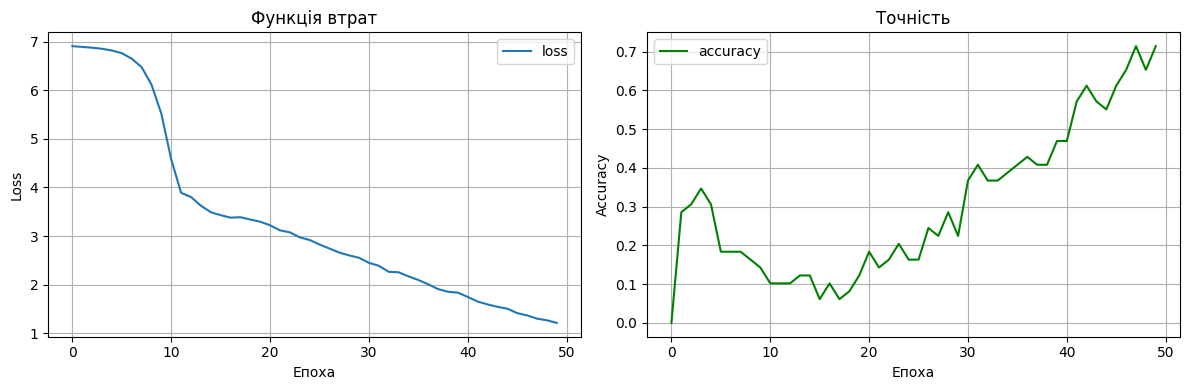

In [8]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='loss')
plt.title('Функція втрат')
plt.xlabel('Епоха')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='accuracy', color='green')
plt.title('Точність')
plt.xlabel('Епоха')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Короткий аналіз: Протягом 50 епох функція втрат (loss) монотонно знижувалася з 6.91 на початку навчання (найрізкіше падіння відбулося між 7-ю та 12-ю епохами — з 6.65 до 3.89) до 1.22 на останній епосі. Точність (accuracy) на перших 4 епохах зросла до 0.35, після чого тимчасово знизилася до 0.06–0.10 (на 11–18 епохах) під час активної перебудови ваг, а починаючи з 20-ї епохи почала стабільно зростати й досягла 0.71 (71.4%) на 50-й епосі.Цих графіків недостатньо, щоб оцінити якість моделі на новому тексті: вони побудовані лише за навчальними даними, без валідаційної вибірки, тому показують, наскільки добре модель запам’ятала навчальний текст, а не наскільки добре вона працює з новим.   

### 9. Генерація нового тексту
Реалізуйте функцію **`buildPhrase(texts, str_len=20)`**, яка:
1. Перетворює початковий текст на індекси слів за допомогою `tokenizer`;
2. На кожному кроці передає моделі **останні `inp_words` індексів**;
3. Отримує прогноз `model.predict()`, визначає індекс найбільш імовірного слова через `argmax`;
4. Додає нове слово до послідовності, використовуючи `tokenizer.index_word`;
5. Повертає згенеровану фразу.

Перевірте роботу функції на початковій фразі **`"Думи мої думи"`**, згенеруйте **20 слів**.

**Зверніть увагу:** початкова фраза має містити щонайменше три відомі токенізатору слова. Якщо слово не знайдено, передбачте зрозумілу обробку цього випадку.

In [9]:
def buildPhrase(texts, str_len=20, model_to_use=None):
    if model_to_use is None:
        model_to_use = model

    data = tokenizer.texts_to_sequences([texts])[0]
    if len(data) < inp_words:
        return 'Помилка: початкова фраза має містити щонайменше 3 відомі слова'

    res = texts
    for i in range(str_len):
        x = np.array([data[-inp_words:]])
        pred = model_to_use.predict(x, verbose=0)
        index = np.argmax(pred)
        data.append(index)
        res += ' ' + tokenizer.index_word.get(index, '?')

    return res

phrase = buildPhrase('Думи мої думи')
print(phrase)

Думи мої думи мені лихо мені нащо вами нащо сміх на папері породило рядами чом чом лихо не не як свою вас вас


## Частина 2. Автоматичний підбір гіперпараметрів (Keras Tuner)

### 10. Встановлення та імпорт Keras Tuner
У Google Colab або Jupyter Notebook встановіть (за потреби) пакет `keras-tuner`. Імпортуйте його під псевдонімом `kt`.

**Підказка:** для встановлення пакета в ноутбуці використовуйте `%pip install keras-tuner`.

Повторно створювати `X` та `Y` не потрібно: використайте вибірку з Частини 1.

In [10]:
%pip install keras-tuner -q
import keras_tuner as kt

### 11. Створення функції `build_model(hp)`
Опишіть функцію, яка будує та компілює модель і дає змогу змінювати гіперпараметри:

| Гіперпараметр | Простір пошуку |
|---|---|
| `embedding_dim` | від 128 до 512, крок 64 |
| `rnn_units` | від 64 до 256, крок 64 |
| `lstm_units` | від 64 до 256, крок 64 |
| `dropout_rate` | від 0.1 до 0.5, крок 0.1 |
| `dense_units` | від 64 до 256, крок 64 |
| `optimizer` | `adam` або `rmsprop` |

Збережіть структуру шарів із Частини 1: `Embedding → SimpleRNN → LSTM → Dropout → Dense → Dense`.

**Підказка:** використовуйте `hp.Int()`, `hp.Float()` і `hp.Choice()`; останній шар має `maxWordsCount` нейронів із `softmax`. Функція `build_model(hp)` повинна повертати скомпільовану модель.

In [11]:
def build_model(hp):
    model = Sequential()
    model.add(Embedding(maxWordsCount,
                        hp.Int('embedding_dim', min_value=128, max_value=512, step=64),
                        input_length=inp_words))
    model.add(SimpleRNN(hp.Int('rnn_units', min_value=64, max_value=256, step=64),
                        activation='tanh', return_sequences=True))
    model.add(LSTM(hp.Int('lstm_units', min_value=64, max_value=256, step=64),
                   activation='tanh'))
    model.add(Dropout(hp.Float('dropout_rate', min_value=0.1, max_value=0.5, step=0.1)))
    model.add(Dense(hp.Int('dense_units', min_value=64, max_value=256, step=64),
                    activation='relu'))
    model.add(Dense(maxWordsCount, activation='softmax'))

    model.compile(optimizer=hp.Choice('optimizer', ['adam', 'rmsprop']),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

### 12. Пошук найкращих параметрів
Створіть `kt.RandomSearch` із такими налаштуваннями, як у вихідному прикладі:
- `hypermodel=build_model` (або передайте `build_model` першим аргументом);
- `objective='accuracy'`;
- `max_trials=10`;
- `executions_per_trial=1`;
- `directory='my_tuning'`, `project_name='text_prediction'`.

Запустіть `tuner.search(X, Y, epochs=10, batch_size=32)`.

**Завдання:** отримайте найкращий набір параметрів через `get_best_hyperparameters(num_trials=1)` і виведіть значення всіх шести гіперпараметрів.

**Примітка:** у вихідному прикладі підбір здійснюється за *навчальною* точністю. Це навчальна демонстрація; для об’єктивнішого порівняння зазвичай використовують окрему валідаційну вибірку.

In [12]:
tuner = kt.RandomSearch(
    build_model,
    objective='accuracy',
    max_trials=10,
    executions_per_trial=1,
    directory='my_tuning',
    project_name='text_prediction'
)

tuner.search(X, Y, epochs=10, batch_size=32)

best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
for name in ['embedding_dim', 'rnn_units', 'lstm_units', 'dropout_rate', 'dense_units', 'optimizer']:
    print(name, '=', best_hps.get(name))

Trial 10 Complete [00h 00m 06s]
accuracy: 0.44897958636283875

Best accuracy So Far: 0.6734693646430969
Total elapsed time: 00h 01m 01s
embedding_dim = 384
rnn_units = 192
lstm_units = 256
dropout_rate = 0.30000000000000004
dense_units = 256
optimizer = adam


### 13. Навчання моделі з підібраними параметрами
Створіть нову модель із найкращими параметрами (`tuner.hypermodel.build(best_hps)`), збережіть її у змінній `best_model`.

Навчіть `best_model` на `X`, `Y` із `batch_size=32`, `epochs=50`. Історію збережіть у `best_history`.

Виведіть `best_model.summary()`, а також кінцеві значення `loss` і `accuracy`.

In [13]:
best_model = tuner.hypermodel.build(best_hps)
best_history = best_model.fit(X, Y, batch_size=32, epochs=50)

best_model.summary()
print('Втрати на останній епосі:', best_history.history['loss'][-1])
print('Точність на останній епосі:', best_history.history['accuracy'][-1])

Epoch 1/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 7s 122ms/step - accuracy: 0.0000e+00 - loss: 6.9072
Epoch 2/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.3061 - loss: 6.8853
Epoch 3/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step - accuracy: 0.4898 - loss: 6.8588
Epoch 4/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - accuracy: 0.4286 - loss: 6.8161
Epoch 5/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step - accuracy: 0.3673 - loss: 6.7307
Epoch 6/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 186ms/step - accuracy: 0.1633 - loss: 6.5917
Epoch 7/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step - accuracy: 0.1429 - loss: 6.2214
Epoch 8/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step - accuracy: 0.1020 - loss: 5.4503
Epoch 9/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 203ms/step - accuracy: 0.1020 - loss: 4.2445
Epoch 10/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step - accuracy: 0.1020 - loss: 3.8388
Epoch 11/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.1429 - loss: 3.6139 
Epoch 12/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.1224 -

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 3, 384)         │       384,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 3, 192)         │       110,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 256)            │       459,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1000)           │       257,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,832,058 (14.62 MB)

 Trainable params: 1,277,352 (4.87 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,554,706 (9.75 MB)

Втрати на останній епосі: 0.19255651533603668
Точність на останній епосі: 0.9795918464660645


### 14. Графіки та генерація тексту після підбору
1. Побудуйте графіки `loss` і `accuracy` для `best_history`.
2. Порівняйте фінальні навчальні показники `model` та `best_model` в одному невеликому виводі або таблиці.
3. Згенеруйте **20 слів** із початкової фрази **`"Думи мої думи"`** за допомогою `best_model` (адаптуйте створену функцію або передайте модель їй як аргумент).
4. Порівняйте два згенеровані тексти.

**Зверніть увагу:** на такому невеликому тексті результати можуть бути нестабільними, а висока навчальна точність не означає якісної генерації нових фраз.

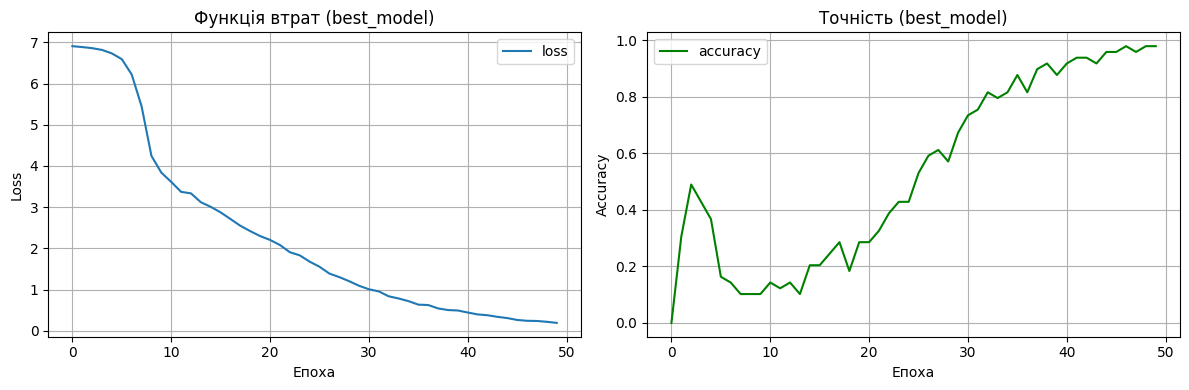

Модель        | loss     | accuracy
model         | 1.2152   | 0.7143
best_model    | 0.1926   | 0.9796

Текст model:      Думи мої думи мені лихо мені нащо вами нащо сміх на папері породило рядами чом чом лихо не не як свою вас вас
Текст best_model: Думи мої думи мені лихо мені нащо вами нащо на на папері сміх рядами чом сльози вітер не затопили в винесли в розмили


In [14]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(best_history.history['loss'], label='loss')
plt.title('Функція втрат (best_model)')
plt.xlabel('Епоха')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(best_history.history['accuracy'], label='accuracy', color='green')
plt.title('Точність (best_model)')
plt.xlabel('Епоха')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

print('Модель        | loss     | accuracy')
print(f"model         | {history.history['loss'][-1]:.4f}   | {history.history['accuracy'][-1]:.4f}")
print(f"best_model    | {best_history.history['loss'][-1]:.4f}   | {best_history.history['accuracy'][-1]:.4f}")

print('\nТекст model:     ', buildPhrase('Думи мої думи'))
print('Текст best_model:', buildPhrase('Думи мої думи', model_to_use=best_model))

## Висновки
Напишіть власний висновок **5–8 речень**, спираючись на отримані результати. Висвітліть:

1. Яку роль виконують шари `Embedding`, `SimpleRNN`, `LSTM` та `Dropout`?
2. Яких значень `loss` і `accuracy` досягла початкова модель?
3. Які гіперпараметри обрав Keras Tuner?
4. Чи покращилися навчальні показники після підбору параметрів?
5. Наскільки зв’язним був згенерований текст і чому обсяг корпусу важливий?

**Висновок студента:**


> У ході лабораторної роботи було побудовано рекурентну нейронну мережу для генерації тексту, де шар **Embedding** перетворює числові індекси слів у щільні векторні представлення, **SimpleRNN** виділяє базові послідовні залежності, **LSTM** фіксує глибший контекст послідовності, а **Dropout** запобігає перенавчанню моделі. Початкова модель після 50 епох навчання досягла значення функції втрат **loss = 1.2152** та точності **accuracy = 0.7143** (71.43%). За допомогою автоматичного пошуку **Keras Tuner** було підібрано оптимальні гіперпараметри: `embedding_dim = 384`, `rnn_units = 192`, `lstm_units = 256`, `dropout_rate = 0.3`, `dense_units = 256` та оптимізатор `adam`. Після навчання оновленої моделі навчальні показники суттєво покращилися: втрати знизилися до **loss = 0.1926**, а точність зросла до **accuracy = 0.9796** (97.96%). Проте згенерований обома моделями текст виявився малозв’язним і містив повтори слів, оскільки модель фактично зазубрила короткий фрагмент вірша з 35 унікальних слів. Для формування граматично правильних і логічно зв’язних фраз критично важливий великий обсяг навчального корпусу, який дозволяє мережі вивчити різноманітні мовні конструкції та узагальнювати контекст.

---

### Що потрібно здати
Заповнений файл `.ipynb` з усім власним кодом, результатами виконання, графіками, двома прикладами згенерованого тексту, знайденими гіперпараметрами та висновками.